# Image dataset: Random Forest

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from models.random_forest import RandomForest
from utils.data import load_train
from utils.evaluation import evaluate_model, print_report, get_confusion_matrix

X, y = load_train("image")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))

Train: (16000, 500)  Validation: (4000, 500)  Classes: 50


## Number of trees

How many trees vote. No preprocessing is used: trees split one feature at a time, so scaling does not change them.

In [2]:
rows = []
best_score = 0

for n_estimators in [10, 25, 50]:
    model = RandomForest(
        n_estimators=n_estimators, max_depth=16, min_samples_split=2,
        min_samples_leaf=5, max_features="sqrt",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"n_estimators": n_estimators, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_n_estimators = metrics["val_accuracy"], n_estimators

display(pd.DataFrame(rows))
print("Kept n_estimators =", best_n_estimators)

,n_estimators,train_accuracy,val_accuracy,val_macro_f1
0,10,0.521250,0.14325,0.129269
1,25,0.717000,0.17950,0.162782
2,50,0.847688,0.20250,0.183485


Kept n_estimators = 50


## Maximum depth

How many questions each tree may ask in a row

In [3]:
rows = []
best_score = 0

for max_depth in [8, 16, 24]:
    model = RandomForest(
        n_estimators=best_n_estimators, max_depth=max_depth, min_samples_split=2,
        min_samples_leaf=5, max_features="sqrt",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"max_depth": max_depth, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_max_depth = metrics["val_accuracy"], max_depth

display(pd.DataFrame(rows))
print("Kept max_depth =", best_max_depth)

,max_depth,train_accuracy,val_accuracy,val_macro_f1
0,8,0.342625,0.15250,0.126880
1,16,0.847688,0.20250,0.183485
2,24,0.985187,0.22325,0.205643


Kept max_depth = 24


## Minimum samples in a leaf

Every final group in a tree must contain at least this many images

In [4]:
rows = []
best_score = 0

for min_samples_leaf in [1, 5, 20]:
    model = RandomForest(
        n_estimators=best_n_estimators, max_depth=best_max_depth, min_samples_split=2,
        min_samples_leaf=min_samples_leaf, max_features="sqrt",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"min_samples_leaf": min_samples_leaf, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_min_samples_leaf = metrics["val_accuracy"], min_samples_leaf

display(pd.DataFrame(rows))
print("Kept min_samples_leaf =", best_min_samples_leaf)

,min_samples_leaf,train_accuracy,val_accuracy,val_macro_f1
0,1,0.997250,0.22025,0.207468
1,5,0.985187,0.22325,0.205643
2,20,0.777687,0.20850,0.183048


Kept min_samples_leaf = 5


## Features per split

How many randomly chosen features each split may look at. Of the 500 features, log2 is 8, sqrt is 22.

In [5]:
rows = []
best_score = 0

for max_features in ["log2", "sqrt", 50]:
    model = RandomForest(
        n_estimators=best_n_estimators, max_depth=best_max_depth, min_samples_split=2,
        min_samples_leaf=best_min_samples_leaf, max_features=max_features,
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"max_features": str(max_features), **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_max_features = metrics["val_accuracy"], max_features

display(pd.DataFrame(rows))
print("Kept max_features =", best_max_features)

,max_features,train_accuracy,val_accuracy,val_macro_f1
0,log2,0.990125,0.21775,0.198926
1,sqrt,0.985187,0.22325,0.205643
2,50,0.971875,0.23425,0.219471


Kept max_features = 50


## Final Model

The hyperparameters we reached and their scores.

n_estimators: 50  max_depth: 24  min_samples_leaf: 5  max_features: 50
{'train_accuracy': 0.971875, 'val_accuracy': 0.23425, 'val_macro_f1': 0.21947115586656632}
              precision    recall  f1-score   support

           0       0.18      0.16      0.17        80
           1       0.19      0.09      0.12        80
           2       0.44      0.60      0.51        80
           3       0.26      0.24      0.25        80
           4       0.27      0.28      0.27        80
           5       0.38      0.59      0.46        80
           6       0.16      0.10      0.12        80
           7       0.26      0.29      0.28        80
           8       0.18      0.21      0.19        80
           9       0.12      0.06      0.08        80
          10       0.16      0.12      0.14        80
          11       0.21      0.33      0.26        80
          12       0.30      0.39      0.34        80
          13       0.29      0.41      0.34        80
          14       0.20    

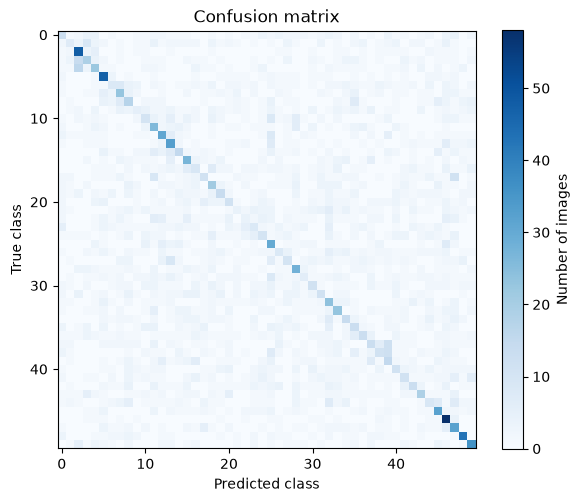

In [6]:
print("n_estimators:", best_n_estimators, " max_depth:", best_max_depth,
      " min_samples_leaf:", best_min_samples_leaf, " max_features:", best_max_features)

model = RandomForest(
    n_estimators=best_n_estimators, max_depth=best_max_depth, min_samples_split=2,
    min_samples_leaf=best_min_samples_leaf, max_features=best_max_features,
)
model.fit(X_train, y_train)

print(evaluate_model(model, X_train, y_train, X_val, y_val))

val_predictions = model.predict(X_val)
print_report(y_val, val_predictions)

# 50 classes: the confusion matrix is shown as a picture instead of a table
labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()